# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Arya Rachman Indrawan
- NIM   : 241011402689
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Inisialisasi Identitas Mahasiswa & Random State
NIM = 241011402689  # NIM Lengkap Mahasiswa
KELAS = "Reg B"     # Kelas yang diambil

# Sesuai ketentuan: random_state = 2 digit terakhir NIM Anda (jika 00, gunakan 100)
RANDOM_STATE = 100 if (NIM % 100) == 0 else (NIM % 100)

# Import Library Utama
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(f"Identitas Mahasiswa:")
print(f"- NIM          : {NIM}")
print(f"- Kelas        : {KELAS}")
print(f"- RANDOM_STATE : {RANDOM_STATE}")

Identitas Mahasiswa:
- NIM          : 241011402689
- Kelas        : Reg B
- RANDOM_STATE : 89


In [2]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

print("Fungsi train_test_split berhasil didefinisikan dan siap digunakan.")

Fungsi train_test_split berhasil didefinisikan dan siap digunakan.


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data.csv:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40 baris
Shape X (BiayaIklan): (40, 1)
Shape y (Penjualan) : (40,)


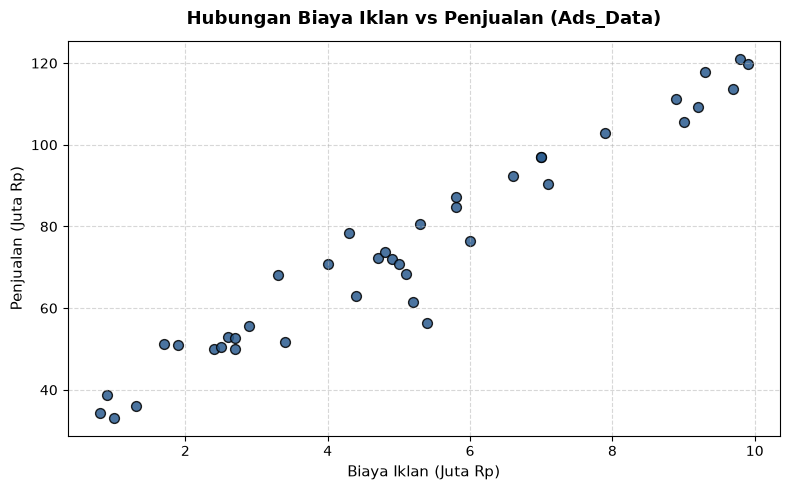

In [3]:
# 1. Baca Ads_Data.csv menggunakan pandas
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data.csv:")
print(df_ads.head())
print(f"\nJumlah baris data: {len(df_ads)} baris")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan), pastikan X berbentuk 2D (n, 1)
X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

print(f"Shape X (BiayaIklan): {X_ads.shape}")
print(f"Shape y (Penjualan) : {y_ads.shape}")

# 3. Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(df_ads['BiayaIklan'], df_ads['Penjualan'], color='#2b5c8f', edgecolors='k', s=50, alpha=0.85)
plt.title('Hubungan Biaya Iklan vs Penjualan (Ads_Data)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Biaya Iklan (Juta Rp)', fontsize=11)
plt.ylabel('Penjualan (Juta Rp)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Split data Ads_Data dengan test_size=0.2 dan random_state=RANDOM_STATE
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Shape X_train : {X_train_ads.shape}")
print(f"Shape X_test  : {X_test_ads.shape}")
print(f"Shape y_train : {y_train_ads.shape}")
print(f"Shape y_test  : {y_test_ads.shape}")

Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# 1. Implementasi LinearRegression dengan Normal Equation (dari materi)
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

# Latih model regresi pada data training
lr_model = LinearRegression()
lr_model.fit(X_train_ads, y_train_ads)

# 2. Tampilkan nilai intercept (b) dan koefisien (m)
b = lr_model.intercept_
m = lr_model.coefficients_[0]

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"\nPersamaan Garis Regresi: ŷ = {b:.4f} + {m:.4f} * BiayaIklan")

Intercept (b) : 27.5570
Koefisien (m) : 9.1762

Persamaan Garis Regresi: ŷ = 27.5570 + 9.1762 * BiayaIklan


**Jawaban A3 (interpretasi):**

Hasil pelatihan *Linear Regression* (normal equation) pada data training dengan `random_state = 89`:

$$\hat{y} = 27.5570 + 9.1762 \cdot \text{BiayaIklan}$$

1. **Intercept ($b = 27.5570$):** estimasi penjualan bulanan ketika biaya iklan 0 juta Rp, yaitu sekitar **27,56 juta Rp**. Perlu diingat bahwa data biaya iklan hanya berada pada rentang 0,8–9,9 juta Rp, jadi nilai ini adalah ekstrapolasi kecil ke titik 0 dan sebaiknya dibaca sebagai "penjualan dasar" yang kasar, bukan angka pasti.
2. **Koefisien ($m = 9.1762$):** bernilai positif, artinya biaya iklan dan penjualan berhubungan searah. **Setiap kenaikan biaya iklan 1 juta Rp, penjualan bulanan diprediksi naik rata-rata sekitar 9,18 juta Rp.**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Implementasi metrik evaluasi regresi dengan NumPy
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Prediksi pada data training dan testing
y_pred_train_ads = lr_model.predict(X_train_ads)
y_pred_test_ads = lr_model.predict(X_test_ads)

# 1. Hitung seluruh metrik
mae_tr = mean_absolute_error(y_train_ads, y_pred_train_ads)
mse_tr = mean_squared_error(y_train_ads, y_pred_train_ads)
rmse_tr = root_mean_squared_error(y_train_ads, y_pred_train_ads)
r2_tr = r2_score(y_train_ads, y_pred_train_ads)

mae_te = mean_absolute_error(y_test_ads, y_pred_test_ads)
mse_te = mean_squared_error(y_test_ads, y_pred_test_ads)
rmse_te = root_mean_squared_error(y_test_ads, y_pred_test_ads)
r2_te = r2_score(y_test_ads, y_pred_test_ads)

# 2. Tampilkan dalam tabel perbandingan
df_metrics_reg = pd.DataFrame({
    'Metrik Evaluasi': ['MAE (Juta Rp)', 'MSE', 'RMSE (Juta Rp)', 'R² Score'],
    'Data Training': [mae_tr, mse_tr, rmse_tr, r2_tr],
    'Data Testing': [mae_te, mse_te, rmse_te, r2_te]
})

print(df_metrics_reg.round(4).to_string(index=False))

Metrik Evaluasi  Data Training  Data Testing
  MAE (Juta Rp)         4.4018        5.0772
            MSE        35.7863       37.6794
 RMSE (Juta Rp)         5.9822        6.1384
       R² Score         0.9456        0.9246


**Jawaban A4 (analisis):**

| Metrik | Training | Testing |
|---|---|---|
| MAE | 4.4018 | 5.0772 |
| MSE | 35.7863 | 37.6794 |
| RMSE | 5.9822 | 6.1384 |
| R² | 0.9456 | 0.9246 |

1. **RMSE:** pada data testing RMSE = **6,14 juta Rp**. Artinya, rata-rata prediksi penjualan meleset sekitar 6,14 juta Rp dari penjualan sebenarnya (dalam satuan yang sama dengan target). RMSE training (5,98) hanya sedikit lebih kecil dari testing.
2. **R²:** pada data testing R² = **0,9246**, yaitu sekitar 92,5% variasi penjualan pada data uji dapat dijelaskan oleh biaya iklan. Sisanya (sekitar 7,5%) dijelaskan faktor lain yang tidak ada di model.
3. **Apakah model sudah baik?** Ya, model ini sudah baik. R² di atas 0,90 dan selisih antara training dan testing kecil (R² 0,9456 vs 0,9246; RMSE 5,98 vs 6,14), jadi tidak terlihat overfitting. Catatan: data testing hanya 8 titik, sehingga angka testing bisa agak bergeser kalau pembagian datanya berbeda.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== Perbandingan Koefisien: Normal Equation vs Gradient Descent (5000 Iterasi) ===
Normal Equation (Target Optimal): b = 27.5570, m = 9.1762

 Learning Rate  Intercept (b)  Koefisien (m)  Final Loss (MSE)
         0.001        18.4763        10.5492           53.2580
         0.020        27.5570         9.1762           35.7863
         0.100            NaN            NaN               NaN


/Users/aryaarach/Projects/Kuliah/Semester 5/machine-learning/2026_class/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/var/folders/26/yy9t1lzx7fv14px85kv72kj80000gn/T/ipykernel_28570/2828879072.py:26: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
/var/folders/26/yy9t1lzx7fv14px85kv72kj80000gn/T/ipykernel_28570/2828879072.py:24: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient


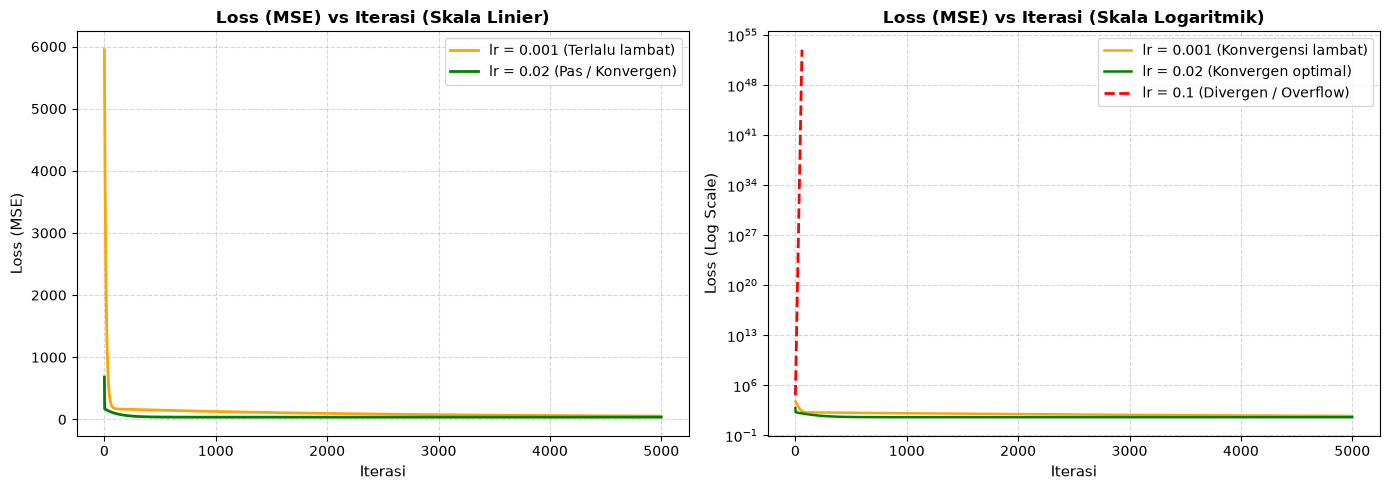

In [7]:
# Implementasi LinearRegressionGD (dari materi)
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

# 1 & 2. Latih model dengan 3 learning rate berbeda
learning_rates = [0.001, 0.02, 0.1]
gd_results = {}

print("=== Perbandingan Koefisien: Normal Equation vs Gradient Descent (5000 Iterasi) ===")
print(f"Normal Equation (Target Optimal): b = {b:.4f}, m = {m:.4f}\n")

summary_gd = []
for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model.fit(X_train_ads, y_train_ads)
    gd_results[lr] = model
    
    b_val = model.intercept_
    m_val = model.coefficients_[0] if model.coefficients_ is not None else np.nan
    final_loss = model.loss_history_[-1] if len(model.loss_history_) > 0 else np.nan
    summary_gd.append({
        'Learning Rate': lr,
        'Intercept (b)': b_val,
        'Koefisien (m)': m_val,
        'Final Loss (MSE)': final_loss
    })

df_summary_gd = pd.DataFrame(summary_gd)
print(df_summary_gd.round(4).to_string(index=False))

# 3. Grafik Loss (MSE) vs Iterasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Skala Linier untuk lr=0.001 dan lr=0.02
axes[0].plot(gd_results[0.001].loss_history_, label='lr = 0.001 (Terlalu lambat)', color='orange', linewidth=2)
axes[0].plot(gd_results[0.02].loss_history_, label='lr = 0.02 (Pas / Konvergen)', color='green', linewidth=2)
axes[0].set_title('Loss (MSE) vs Iterasi (Skala Linier)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Iterasi', fontsize=11)
axes[0].set_ylabel('Loss (MSE)', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Skala Logaritmik untuk menampilkan dinamika ketiga learning rate
axes[1].plot(gd_results[0.001].loss_history_, label='lr = 0.001 (Konvergensi lambat)', color='orange', linewidth=1.8)
axes[1].plot(gd_results[0.02].loss_history_, label='lr = 0.02 (Konvergen optimal)', color='green', linewidth=1.8)

# Menangani overflow lr=0.1
loss_01 = np.array(gd_results[0.1].loss_history_)
valid_indices = np.where(np.isfinite(loss_01))[0]
if len(valid_indices) > 0:
    plot_len = min(60, len(valid_indices))
    axes[1].plot(valid_indices[:plot_len], loss_01[valid_indices[:plot_len]], 
                 label='lr = 0.1 (Divergen / Overflow)', color='red', linestyle='--', linewidth=2)

axes[1].set_yscale('log')
axes[1].set_title('Loss (MSE) vs Iterasi (Skala Logaritmik)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Iterasi', fontsize=11)
axes[1].set_ylabel('Loss (Log Scale)', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

| Learning rate | Intercept (b) | Koefisien (m) | Loss akhir (MSE) |
|---|---|---|---|
| Normal equation | 27.5570 | 9.1762 | 35.7863 |
| 0.001 | 18.4763 | 10.5492 | 53.2580 |
| 0.02 | 27.5570 | 9.1762 | 35.7863 |
| 0.1 | NaN | NaN | NaN |

1. **lr = 0.001 (terlalu lambat):** setelah 5000 iterasi parameternya masih jauh dari solusi normal equation (b = 18,48 vs 27,56; m = 10,55 vs 9,18) dan loss masih 53,26. Kurva loss turun mulus tanpa osilasi tetapi masih menurun saat iterasi berhenti. Langkah update ($\alpha \times$ gradien) terlalu kecil sehingga 5000 iterasi tidak cukup.
2. **lr = 0.02 (pas):** loss turun cepat (dari sekitar 683 pada iterasi pertama menjadi sekitar 38 pada iterasi ke-500), lalu mendatar. Parameternya sudah berselisih kurang dari 0,001 dari normal equation sejak sekitar iterasi ke-2.400, dan hasil akhirnya sama dengan normal equation (b = 27,5570, m = 9,1762).
3. **lr = 0.1 (divergen):** loss justru membesar di setiap iterasi (iterasi pertama sudah sekitar 41.000, lalu naik berlipat), sampai melewati batas bilangan floating point sekitar iterasi ke-370 dan menjadi `inf`, lalu `NaN`. Itulah arti `RuntimeWarning: overflow`. Penyebabnya, langkah update terlalu besar sehingga melompati titik minimum dan mendarat di sisi seberang yang lebih curam (*overshooting*). Karena nilai `BiayaIklan` mencapai 9,9, gradiennya cukup besar sehingga learning rate yang aman jadi kecil. Pada data ini 0,02 masih stabil, sedangkan 0,1 tidak.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

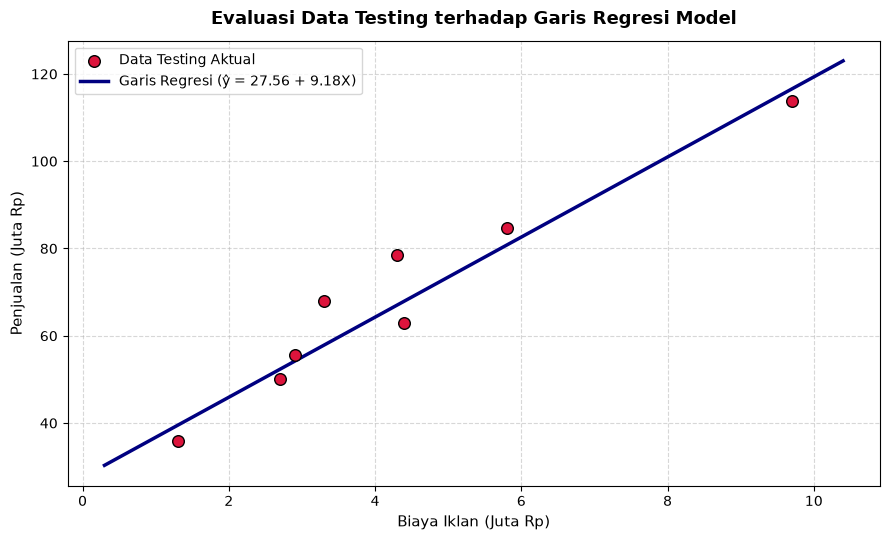

Rentang Biaya Iklan pada Dataset: [0.8, 9.9] Juta Rp

 Biaya Iklan (Juta Rp)  Prediksi Penjualan (Juta Rp)                   Kategori Prediksi
                   4.5                       68.8502         Interpolasi (dalam rentang)
                   7.0                       91.7908  Interpolasi (mendekati batas atas)
                  12.0                      137.6720 Ekstrapolasi (di luar rentang data)


In [8]:
# 1. Scatter data testing beserta garis regresi model
plt.figure(figsize=(9, 5.5))
plt.scatter(X_test_ads, y_test_ads, color='crimson', label='Data Testing Aktual', edgecolors='k', s=70, zorder=3)

# Garis regresi diplot sepanjang domain data
x_plot_range = np.linspace(df_ads['BiayaIklan'].min() - 0.5, df_ads['BiayaIklan'].max() + 0.5, 100).reshape(-1, 1)
y_plot_pred = lr_model.predict(x_plot_range)
plt.plot(x_plot_range, y_plot_pred, color='navy', linewidth=2.5, label=f'Garis Regresi (ŷ = {b:.2f} + {m:.2f}X)')

plt.title('Evaluasi Data Testing terhadap Garis Regresi Model', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Biaya Iklan (Juta Rp)', fontsize=11)
plt.ylabel('Penjualan (Juta Rp)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta
biaya_skenario = np.array([[4.5], [7.0], [12.0]])
prediksi_hasil = lr_model.predict(biaya_skenario)

df_prediksi = pd.DataFrame({
    'Biaya Iklan (Juta Rp)': biaya_skenario.ravel(),
    'Prediksi Penjualan (Juta Rp)': prediksi_hasil.ravel(),
    'Kategori Prediksi': ['Interpolasi (dalam rentang)', 'Interpolasi (mendekati batas atas)', 'Ekstrapolasi (di luar rentang data)']
})

print(f"Rentang Biaya Iklan pada Dataset: [{df_ads['BiayaIklan'].min():.1f}, {df_ads['BiayaIklan'].max():.1f}] Juta Rp\n")
print(df_prediksi.round(4).to_string(index=False))

**Jawaban A6 (analisis):**

1. **Hasil prediksi:**
   - Biaya iklan 4,5 juta Rp → prediksi penjualan **68,85 juta Rp**
   - Biaya iklan 7 juta Rp → prediksi penjualan **91,79 juta Rp**
   - Biaya iklan 12 juta Rp → prediksi penjualan **137,67 juta Rp**
2. **Seberapa bisa dipercaya untuk 12 juta Rp?** Kurang bisa dipercaya. Data biaya iklan hanya mencakup 0,8–9,9 juta Rp, sehingga 12 juta berada di luar rentang yang pernah dilihat model (ekstrapolasi). Model linear mengasumsikan kenaikan penjualan tetap 9,18 juta Rp per 1 juta Rp iklan tanpa batas, padahal di dunia nyata efek iklan biasanya melandai (*diminishing returns*, pasar jenuh). Karena itu angka 137,67 juta Rp bisa terlalu optimis. Prediksi 4,5 dan 7 juta berada di dalam rentang data (interpolasi) sehingga jauh lebih dapat diandalkan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email_Data.csv:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Distribusi Label Target:
- Bukan Spam (0) : 35 email
- Spam (1)       : 25 email
- Total Sampel   : 60 email
Shape X : (60, 2)
Shape y : (60,)


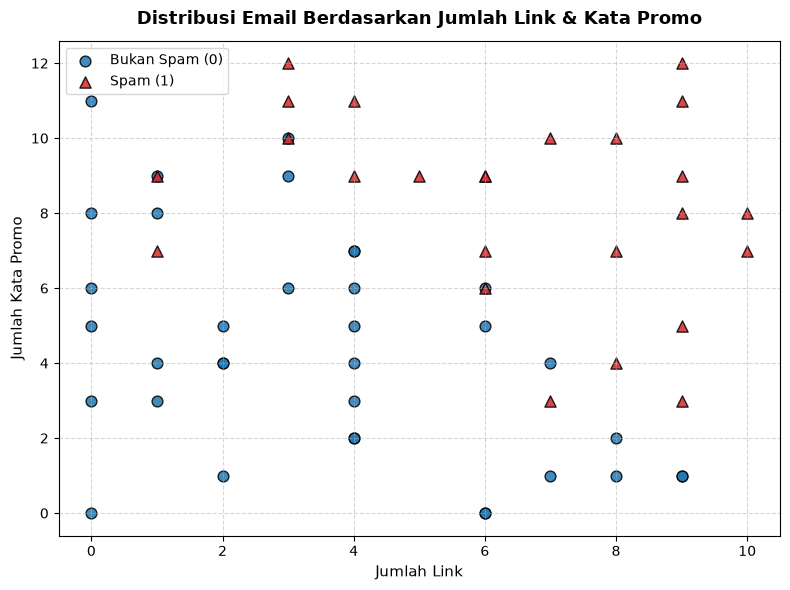

In [9]:
# 1. Baca Email_Data.csv dan tampilkan 5 data pertama
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data.csv:")
print(df_email.head())

distribusi_email = df_email['Spam'].value_counts()
print(f"\nDistribusi Label Target:")
print(f"- Bukan Spam (0) : {distribusi_email.get(0, 0)} email")
print(f"- Spam (1)       : {distribusi_email.get(1, 0)} email")
print(f"- Total Sampel   : {len(df_email)} email")

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

print(f"Shape X : {X_email.shape}")
print(f"Shape y : {y_email.shape}")

# 3. Scatter plot JumlahLink vs KataPromo
plt.figure(figsize=(8, 6))
mask_not_spam = (df_email['Spam'] == 0)
mask_spam = (df_email['Spam'] == 1)

plt.scatter(df_email.loc[mask_not_spam, 'JumlahLink'], df_email.loc[mask_not_spam, 'KataPromo'],
            color='#1f77b4', label='Bukan Spam (0)', edgecolors='k', s=60, alpha=0.85)
plt.scatter(df_email.loc[mask_spam, 'JumlahLink'], df_email.loc[mask_spam, 'KataPromo'],
            color='#d62728', label='Spam (1)', marker='^', edgecolors='k', s=65, alpha=0.85)

plt.title('Distribusi Email Berdasarkan Jumlah Link & Kata Promo', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Jumlah Link', fontsize=11)
plt.ylabel('Jumlah Kata Promo', fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape X_train : (45, 2), y_train: (45,)
Shape X_test  : (15, 2), y_test : (15,)

Intercept (b)      : -12.5226
Koefisien 1 (m1)   : 1.0106 (JumlahLink)
Koefisien 2 (m2)   : 1.0251 (KataPromo)

Persamaan Peluang:
P(Spam) = σ(-12.5226 + 1.0106 * JumlahLink + 1.0251 * KataPromo)


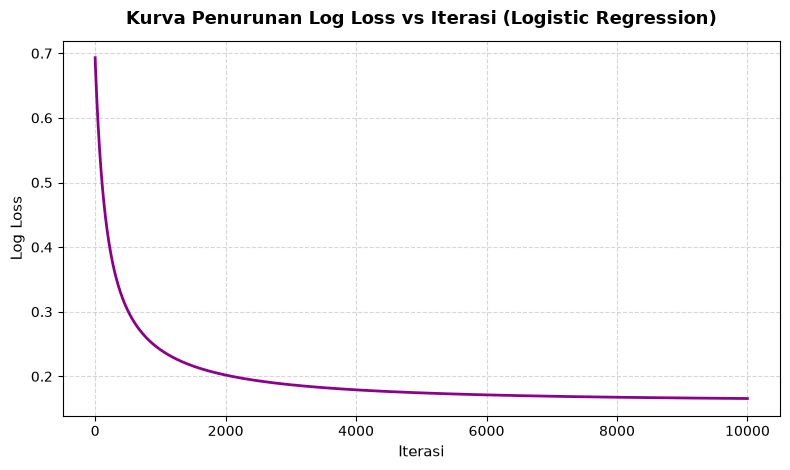

Initial Log Loss : 0.6931
Final Log Loss   : 0.1657


In [10]:
# 1. Split data dengan test_size=0.25 dan random_state=RANDOM_STATE
X_train_em, X_test_em, y_train_em, y_test_em = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

print(f"Shape X_train : {X_train_em.shape}, y_train: {y_train_em.shape}")
print(f"Shape X_test  : {X_test_em.shape}, y_test : {y_test_em.shape}")

# 2. Implementasi LogisticRegression (dari materi)
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Latih model LogisticRegression
log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_reg.fit(X_train_em, y_train_em)

# 3. Tampilkan intercept dan koefisien
b_log = log_reg.intercept_
m1_log = log_reg.coefficients_[0]
m2_log = log_reg.coefficients_[1]

print(f"\nIntercept (b)      : {b_log:.4f}")
print(f"Koefisien 1 (m1)   : {m1_log:.4f} (JumlahLink)")
print(f"Koefisien 2 (m2)   : {m2_log:.4f} (KataPromo)")
print(f"\nPersamaan Peluang:")
print(f"P(Spam) = σ({b_log:.4f} + {m1_log:.4f} * JumlahLink + {m2_log:.4f} * KataPromo)")

# 4. Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 4.8))
plt.plot(log_reg.loss_history_, color='darkmagenta', linewidth=2)
plt.title('Kurva Penurunan Log Loss vs Iterasi (Logistic Regression)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Iterasi', fontsize=11)
plt.ylabel('Log Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Initial Log Loss : {log_reg.loss_history_[0]:.4f}")
print(f"Final Log Loss   : {log_reg.loss_history_[-1]:.4f}")

**Jawaban B2 (analisis):**

1. **Parameter dan persamaan:** $b = -12.5226$, $m_1 = 1.0106$ (`JumlahLink`), $m_2 = 1.0251$ (`KataPromo`).
   $$P(\text{Spam}) = \sigma(-12.5226 + 1.0106 \cdot \text{JumlahLink} + 1.0251 \cdot \text{KataPromo})$$
   Kedua koefisien positif dan hampir sama besar. Setiap tambahan 1 link mengalikan *odds* spam sekitar $e^{1.0106} \approx 2{,}75$ kali, dan setiap tambahan 1 kata promo sekitar $e^{1.0251} \approx 2{,}79$ kali (dengan fitur lain tetap). Jadi kedua fitur sama-sama menaikkan peluang spam dengan pengaruh yang hampir setara.
2. **Kurva log loss:** log loss turun dari 0,6931 (tebakan 50:50 saat bobot = 0) menjadi sekitar 0,507 (iterasi ke-100), 0,302 (ke-500), 0,241 (ke-1.000), 0,174 (ke-5.000), dan **0,1657** pada iterasi ke-10.000. Penurunannya tajam di awal lalu melandai. Pada 1.000 iterasi terakhir loss hanya turun sekitar 0,0008, jadi sudah hampir stabil, tetapi belum benar-benar mencapai titik optimum (lihat perbandingan dengan scikit-learn pada bagian Bonus).

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Implementasi metrik evaluasi klasifikasi
def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp],
                     [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp = cm[1, 1]
    fp = cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp = cm[1, 1]
    fn = cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0

# 1. Evaluasi pada data testing (threshold default = 0.5)
y_pred_test_em = log_reg.predict(X_test_em, threshold=0.5)

cm_test = confusion_matrix(y_test_em, y_pred_test_em)
acc_test = accuracy_score(y_test_em, y_pred_test_em)
prec_test = precision_score(y_test_em, y_pred_test_em)
rec_test = recall_score(y_test_em, y_pred_test_em)
f1_test = f1_score(y_test_em, y_pred_test_em)

print("=== Confusion Matrix (Data Testing) ===")
print(f"[[TN = {cm_test[0,0]},  FP = {cm_test[0,1]}],")
print(f" [FN = {cm_test[1,0]},  TP = {cm_test[1,1]}]]\n")

df_eval_b3 = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Nilai Testing': [acc_test, prec_test, rec_test, f1_test]
})
print(df_eval_b3.round(4).to_string(index=False))

=== Confusion Matrix (Data Testing) ===
[[TN = 4,  FP = 0],
 [FN = 4,  TP = 7]]

   Metrik  Nilai Testing
 Accuracy         0.7333
Precision         1.0000
   Recall         0.6364
 F1-Score         0.7778


**Jawaban B3 (analisis):**

1. **Hasil pada data testing (threshold 0,5), 15 email:**

   | | Prediksi Bukan Spam | Prediksi Spam |
   |---|---|---|
   | **Aktual Bukan Spam** | TN = 4 | FP = 0 |
   | **Aktual Spam** | FN = 4 | TP = 7 |

   Accuracy = **73,33%**, Precision = **100%**, Recall = **63,64%**, F1-score = **77,78%**. Akurasi pada data training adalah 93,33%, lebih tinggi dari testing; karena data testing hanya 15 email, selisih ini sebagian bisa berasal dari sampel yang kecil.
2. **Arti FP dan FN pada filter spam:**
   - **FP (*false positive*):** email yang sebenarnya bukan spam tetapi salah dikira spam, misalnya email tagihan, OTP, atau pengumuman kampus yang masuk ke folder Spam.
   - **FN (*false negative*):** email spam yang lolos dan masuk ke inbox.
3. **Kesalahan yang lebih merugikan: FP.** Email spam yang lolos cukup dihapus manual, sedangkan email penting yang masuk folder Spam bisa tidak terbaca dan menimbulkan kerugian nyata (kehilangan informasi atau tenggat). Karena itu filter spam sebaiknya menjaga *precision* tinggi. Pada model ini precision sudah 100% (tidak ada FP), tetapi recall hanya 63,64% sehingga 4 dari 11 spam masih lolos ke inbox.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

=== Persamaan Decision Boundary ===
b + m1 * x1 + m2 * x2 = 0
x2 (KataPromo) = -(-12.5226 + 1.0106 * x1) / 1.0251
x2 (KataPromo) = 12.2164 + (-0.9859) * JumlahLink



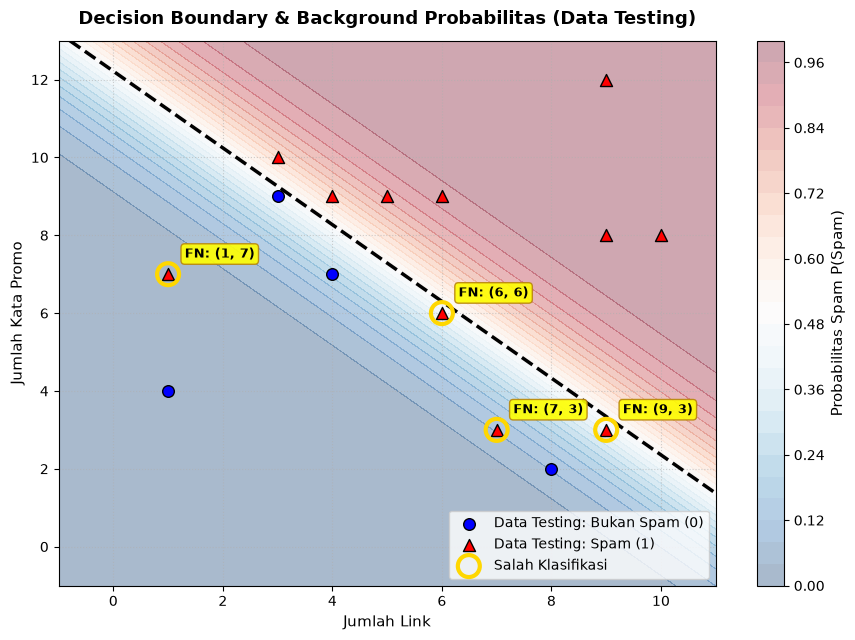

Jumlah data testing yang salah diklasifikasikan: 4 dari 15

Data testing ke-4 (False Negative):
- Fitur       : JumlahLink = 9, KataPromo = 3
- Label Asli  : 1 (Spam)
- Prediksi    : 0 (Bukan Spam)
- Probabilitas Spam: 0.4128
Data testing ke-5 (False Negative):
- Fitur       : JumlahLink = 6, KataPromo = 6
- Label Asli  : 1 (Spam)
- Prediksi    : 0 (Bukan Spam)
- Probabilitas Spam: 0.4234
Data testing ke-11 (False Negative):
- Fitur       : JumlahLink = 7, KataPromo = 3
- Label Asli  : 1 (Spam)
- Prediksi    : 0 (Bukan Spam)
- Probabilitas Spam: 0.0852
Data testing ke-12 (False Negative):
- Fitur       : JumlahLink = 1, KataPromo = 7
- Label Asli  : 1 (Spam)
- Prediksi    : 0 (Bukan Spam)
- Probabilitas Spam: 0.0129


In [12]:
# 1. Persamaan Decision Boundary (saat P(Spam) = 0.5, b + m1*x1 + m2*x2 = 0)
slope_boundary = -m1_log / m2_log
intercept_boundary = -b_log / m2_log

print("=== Persamaan Decision Boundary ===")
print(f"b + m1 * x1 + m2 * x2 = 0")
print(f"x2 (KataPromo) = -({b_log:.4f} + {m1_log:.4f} * x1) / {m2_log:.4f}")
print(f"x2 (KataPromo) = {intercept_boundary:.4f} + ({slope_boundary:.4f}) * JumlahLink\n")

# 2. Visualisasi data testing dengan contourf probabilitas & decision boundary
plt.figure(figsize=(9, 6.5))

# Buat grid kontur probabilitas
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 250), np.linspace(x2_min, x2_max, 250))
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs_grid = log_reg.predict_proba(grid_points).reshape(xx1.shape)

# Background probabilitas
contour = plt.contourf(xx1, xx2, probs_grid, levels=25, cmap='RdBu_r', alpha=0.35)
cbar = plt.colorbar(contour)
cbar.set_label('Probabilitas Spam P(Spam)', fontsize=11)

# Garis batas keputusan (P = 0.5)
plt.contour(xx1, xx2, probs_grid, levels=[0.5], colors='black', linewidths=2.5, linestyles='--')

# Plot data testing
mask_te_not_spam = (y_test_em == 0)
mask_te_spam = (y_test_em == 1)

plt.scatter(X_test_em[mask_te_not_spam, 0], X_test_em[mask_te_not_spam, 1],
            color='blue', edgecolors='k', s=70, label='Data Testing: Bukan Spam (0)', zorder=4)
plt.scatter(X_test_em[mask_te_spam, 0], X_test_em[mask_te_spam, 1],
            color='red', marker='^', edgecolors='k', s=75, label='Data Testing: Spam (1)', zorder=4)

# 3. Beri penanda visual pada data testing yang salah diklasifikasikan
misclassified = (y_pred_test_em != y_test_em)
nama_kelas = {0: 'Bukan Spam', 1: 'Spam'}
idx_salah = np.where(misclassified)[0]

for n, idx in enumerate(idx_salah):
    # Jenis kesalahan ditentukan dari label asli: asli Spam tapi diprediksi Bukan Spam = FN, kebalikannya = FP
    jenis = 'FN' if y_test_em[idx] == 1 else 'FP'
    plt.scatter(X_test_em[idx, 0], X_test_em[idx, 1],
                s=250, facecolors='none', edgecolors='gold', linewidths=3,
                label='Salah Klasifikasi' if n == 0 else "", zorder=5)
    plt.annotate(f"{jenis}: ({X_test_em[idx,0]}, {X_test_em[idx,1]})",
                 (X_test_em[idx, 0], X_test_em[idx, 1]),
                 textcoords="offset points", xytext=(12, 12),
                 bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="darkgoldenrod", alpha=0.9),
                 fontweight='bold', fontsize=9, zorder=6)

plt.title('Decision Boundary & Background Probabilitas (Data Testing)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Jumlah Link', fontsize=11)
plt.ylabel('Jumlah Kata Promo', fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Cetak detail sampel yang salah
print(f"Jumlah data testing yang salah diklasifikasikan: {len(idx_salah)} dari {len(y_test_em)}\n")
for idx in idx_salah:
    prob_val = log_reg.predict_proba(X_test_em[idx:idx+1])[0]
    jenis = 'False Negative' if y_test_em[idx] == 1 else 'False Positive'
    print(f"Data testing ke-{idx} ({jenis}):")
    print(f"- Fitur       : JumlahLink = {X_test_em[idx,0]}, KataPromo = {X_test_em[idx,1]}")
    print(f"- Label Asli  : {y_test_em[idx]} ({nama_kelas[y_test_em[idx]]})")
    print(f"- Prediksi    : {y_pred_test_em[idx]} ({nama_kelas[y_pred_test_em[idx]]})")
    print(f"- Probabilitas Spam: {prob_val:.4f}")


**Jawaban B4 (analisis):**

1. **Persamaan decision boundary:** garis batas berada pada $P(\text{Spam}) = 0.5$, yaitu saat $b + m_1 x_1 + m_2 x_2 = 0$:
   $$x_2 = -\frac{-12.5226 + 1.0106\, x_1}{1.0251} = 12.2164 - 0.9859\, x_1$$
   Titik di atas garis diprediksi Spam (peluang > 0,5), titik di bawah garis diprediksi Bukan Spam.
2. **Data testing yang salah klasifikasi:** ada **4 dari 15** titik, dan keempatnya adalah **False Negative** (aslinya Spam tetapi diprediksi Bukan Spam):

   | JumlahLink | KataPromo | P(Spam) |
   |---|---|---|
   | 9 | 3 | 0,4128 |
   | 6 | 6 | 0,4234 |
   | 7 | 3 | 0,0852 |
   | 1 | 7 | 0,0129 |

   Dua titik pertama berada dekat garis batas (peluang sekitar 0,41–0,42), sehingga hanya sedikit di bawah ambang 0,5. Dua titik lainnya punya salah satu fitur yang rendah (kata promo 3 atau link 1), sehingga model memberi peluang spam yang sangat kecil walaupun email tersebut sebenarnya spam. Model linear dengan dua fitur ini memang sulit menangkap spam yang hanya "kuat" di satu fitur.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# 1 & 2. Eksperimen Threshold (0.3, 0.5, 0.7)
probs_te_email = log_reg.predict_proba(X_test_em)

threshold_list = [0.3, 0.5, 0.7]
rows_th = []

for th in threshold_list:
    preds = (probs_te_email >= th).astype(int)
    cm_ = confusion_matrix(y_test_em, preds)
    tn, fp = cm_[0, 0], cm_[0, 1]
    fn, tp = cm_[1, 0], cm_[1, 1]
    
    prec_ = precision_score(y_test_em, preds)
    rec_ = recall_score(y_test_em, preds)
    acc_ = accuracy_score(y_test_em, preds)
    f1_ = f1_score(y_test_em, preds)
    
    rows_th.append({
        'Threshold': th,
        'Confusion Matrix [[TN, FP], [FN, TP]]': f"[[{tn}, {fp}], [{fn}, {tp}]]",
        'Precision': prec_,
        'Recall': rec_,
        'Accuracy': acc_,
        'F1-Score': f1_
    })

df_exp_threshold = pd.DataFrame(rows_th)
print(df_exp_threshold.round(4).to_string(index=False))

 Threshold Confusion Matrix [[TN, FP], [FN, TP]]  Precision  Recall  Accuracy  F1-Score
       0.3                      [[3, 1], [2, 9]]        0.9  0.8182    0.8000    0.8571
       0.5                      [[4, 0], [4, 7]]        1.0  0.6364    0.7333    0.7778
       0.7                      [[4, 0], [6, 5]]        1.0  0.4545    0.6000    0.6250


**Jawaban B5 (analisis):**

| Threshold | [[TN, FP], [FN, TP]] | Precision | Recall |
|---|---|---|---|
| 0.3 | [[3, 1], [2, 9]] | 0.9000 | 0.8182 |
| 0.5 | [[4, 0], [4, 7]] | 1.0000 | 0.6364 |
| 0.7 | [[4, 0], [6, 5]] | 1.0000 | 0.4545 |

1. **Pengaruh threshold:** menurunkan threshold membuat model lebih mudah menyebut "Spam". Recall naik (0,64 → 0,82 pada threshold 0,3) tetapi muncul 1 FP sehingga precision turun menjadi 0,90. Menaikkan threshold membuat model lebih ketat. Pada 0,7 tidak ada FP, tetapi recall turun menjadi 0,45 (6 dari 11 spam lolos). Jadi precision dan recall saling tukar (*trade-off*).
2. **Threshold yang dipilih: 0,5.** Berdasarkan B3, FP lebih merugikan daripada FN. Pada 0,5 FP sudah 0 dan precision 1,0. Menaikkan ke 0,7 tidak menambah precision (sudah maksimal) tetapi menurunkan recall banyak, sehingga tidak ada keuntungan. Menurunkan ke 0,3 menaikkan recall tetapi menambah 1 FP (email sah masuk Spam), yang menurut B3 lebih mahal harganya. Catatan: data testing hanya 15 email, jadi pilihan ini perlu dikonfirmasi pada data yang lebih banyak.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Data email baru
email_baru_list = [
    {'Email': 'E1', 'JumlahLink': 1, 'KataPromo': 2},
    {'Email': 'E2', 'JumlahLink': 5, 'KataPromo': 6},
    {'Email': 'E3', 'JumlahLink': 9, 'KataPromo': 10},
    {'Email': 'E4', 'JumlahLink': 2, 'KataPromo': 11}
]

df_email_baru = pd.DataFrame(email_baru_list)
X_baru = df_email_baru[['JumlahLink', 'KataPromo']].values

# Hitung probabilitas spam
probs_baru = log_reg.predict_proba(X_baru)

# Threshold terpilih dari Soal B5 (threshold = 0.5)
THRESHOLD_PILIHAN = 0.5

df_email_baru['Probabilitas Spam P(Spam)'] = probs_baru
df_email_baru['Prediksi (th=0.3)'] = ['Spam (1)' if p >= 0.3 else 'Bukan Spam (0)' for p in probs_baru]
df_email_baru['Prediksi (th=0.7)'] = ['Spam (1)' if p >= 0.7 else 'Bukan Spam (0)' for p in probs_baru]
df_email_baru[f'Prediksi Terpilih (th={THRESHOLD_PILIHAN})'] = ['Spam (1)' if p >= THRESHOLD_PILIHAN else 'Bukan Spam (0)' for p in probs_baru]

print(f"=== Prediksi Email Baru Menggunakan Threshold Terpilih ({THRESHOLD_PILIHAN}) ===")
print(df_email_baru.round(4).to_string(index=False))

=== Prediksi Email Baru Menggunakan Threshold Terpilih (0.5) ===
Email  JumlahLink  KataPromo  Probabilitas Spam P(Spam) Prediksi (th=0.3) Prediksi (th=0.7) Prediksi Terpilih (th=0.5)
   E1           1          2                     0.0001    Bukan Spam (0)    Bukan Spam (0)             Bukan Spam (0)
   E2           5          6                     0.2109    Bukan Spam (0)    Bukan Spam (0)             Bukan Spam (0)
   E3           9         10                     0.9989          Spam (1)          Spam (1)                   Spam (1)
   E4           2         11                     0.6844          Spam (1)    Bukan Spam (0)                   Spam (1)


**Jawaban B6 (analisis):**

Dengan threshold terpilih 0,5:

| Email | JumlahLink | KataPromo | P(Spam) | Prediksi |
|---|---|---|---|---|
| E1 | 1 | 2 | 0.0001 | Bukan Spam |
| E2 | 5 | 6 | 0.2109 | Bukan Spam |
| E3 | 9 | 10 | 0.9989 | Spam |
| E4 | 2 | 11 | 0.6844 | Spam |

E1 dan E3 jelas (sangat rendah dan sangat tinggi). E2 berada di tengah tetapi masih di bawah garis batas. E4 punya kata promo sangat tinggi dengan link sedikit; peluangnya 0,68 sehingga diprediksi Spam pada threshold 0,5 (dan 0,3), tetapi akan lolos sebagai Bukan Spam jika threshold dinaikkan ke 0,7. Ini contoh nyata bagaimana pilihan threshold mengubah hasil.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression digolongkan sebagai algoritma **klasifikasi** karena tujuan utamanya adalah memprediksi probabilitas keanggotaan kelas diskrit (misalnya kelas biner 0 atau 1) dari suatu sampel data, bukan mengestimasi besaran nilai numerik kontinu. Nama *"regression"* disematkan karena secara internal model ini memodelkan hubungan linear terhadap rasio logaritma peluang (*log-odds* atau *logit*): $z = b + \sum m_i x_i$. Di sinilah peran krusial fungsi **sigmoid** ($\sigma(z) = \frac{1}{1 + e^{-z}}$), yaitu bertindak sebagai fungsi aktivasi non-linear yang memetakan rentang nilai linear $z$ yang tak terbatas $(-\infty, +\infty)$ ke dalam rentang probabilitas tertutup $[0, 1]$, sehingga hasil keluarannya dapat diinterpretasikan secara sahih sebagai probabilitas peluang kelas.

**Jawaban C2:**
Perbedaan mendasar antara *Normal Equation* dan *Gradient Descent* terletak pada pendekatan pencarian parameter optimal model:
- **Normal Equation** merupakan metode solusi tertutup (*closed-form analytical solution*) yang menghitung nilai bobot optimal secara instan dalam satu kali langkah operasi aljabar matriks: $\boldsymbol{\beta} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$. Metode ini tidak memerlukan penentuan *hyperparameter learning rate* maupun iterasi berulang, namun memiliki beban komputasi yang sangat mahal yaitu $\mathcal{O}(d^3)$ karena operasi inversi matriks, di mana $d$ adalah jumlah fitur.
- **Gradient Descent** merupakan metode optimasi numerik iteratif yang memperbarui nilai bobot secara bertahap menuruni gradien fungsi loss: $\boldsymbol{\beta} \leftarrow \boldsymbol{\beta} - \alpha \nabla L$.
- **Kapan sebaiknya memakai Gradient Descent:** Gradient Descent sebaiknya digunakan ketika jumlah sampel data ($n$) atau jumlah fitur ($d$) sangat besar (misalnya ribuan hingga jutaan fitur), ketika kapasitas RAM terbatas untuk melakukan inversi matriks, atau jika matriks fitur bersifat singular/non-invertible (*multicollinearity* tinggi).

**Jawaban C3:**
Model machine learning wajib dievaluasi pada **data testing** karena tujuan utama pemodelan adalah kemampuan **generalisasi**, yaitu mengukur seberapa akurat model mampu memprediksi data baru yang belum pernah dilihat sebelumnya dalam kondisi operasional riil. Jika evaluasi hanya dilakukan pada data training, kita tidak akan pernah mengetahui apakah model benar-benar mempelajari pola fundamental atau hanya sekadar menghafal sampel latih. **Overfitting** adalah suatu kondisi patologis di mana model terlalu kompleks sehingga mempelajari detail noise dan fluktuasi acak pada data training secara berlebihan. Karakteristik khas dari overfitting adalah performa model terlihat sempurna pada data training (error mendekati nol), namun akurasinya jatuh drastis saat diuji pada data testing (*poor generalization*).

**Jawaban C4:**
Pemilihan fungsi loss disesuaikan secara matematis dengan tipe output dan asumsi distribusi probabilitas dari masing-masing model:
- Pada **Linear Regression**, target output ($\hat{y}$) bertipe kontinu $(-\infty, +\infty)$ dengan asumsi galat (*residual*) berdistribusi normal (Gaussian). Berdasarkan prinsip *Maximum Likelihood Estimation* (MLE), fungsi objektif yang diturunkan adalah meminimalkan jumlah kuadrat galat, yaitu **MSE (Mean Squared Error)**. Kurva MSE pada regresi linear bersifat cembung (*strictly convex*) dengan satu titik minimum global yang mudah dicapai.
- Pada **Logistic Regression**, target outputnya adalah estimasi probabilitas $p \in [0, 1]$ yang mengikuti distribusi Bernoulli. Jika MSE diterapkan pada kombinasi linear yang dilewatkan fungsi non-linear sigmoid, fungsi loss yang terbentuk akan menjadi **non-convex** (bergelombang dengan banyak *local minima* yang menjebak gradien). Oleh sebab itu, diturunkan melalui MLE Bernoulli, digunakan **Log Loss (Cross-Entropy Loss)** yang menjamin fungsi loss tetap berbentuk *convex* sekaligus memberikan penalti logaritmik yang sangat tegas (mendekati $\infty$) apabila model memprediksi probabilitas dengan keyakinan tinggi namun ternyata salah total.

**Jawaban C5:**
Hasil numerik (koefisien regresi, intercept, nilai metrik akurasi, hingga visualisasi) dapat berbeda antara satu mahasiswa dengan mahasiswa lainnya karena adanya perbedaan nilai **`random_state` yang dikaitkan dengan 2 digit terakhir NIM masing-masing**. Parameter `random_state` mengatur generator bilangan acak (*pseudo-random number generator*) saat mempartisi baris data dalam fungsi `train_test_split`. Karena setiap mahasiswa memiliki seed acak yang berlainan, kombinasi sampel data yang terambil ke dalam set training dan set testing pada setiap mahasiswa menjadi unik. Perbedaan komposisi data latihan tersebut secara alamiah menghasilkan perbedaan gradien optimasi dan garis keputusan akhir, meskipun algoritma matematika dan dataset mentah yang digunakan sama persis.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Import modul LinearRegression dan LogisticRegression dari scikit-learn
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

print("=== 1. PERBANDINGAN LINEAR REGRESSION ===")
# Latih LinearRegression dari scikit-learn pada data training yang sama persis
sk_lin = SkLinearRegression()
sk_lin.fit(X_train_ads, y_train_ads)
y_pred_sk_ads = sk_lin.predict(X_test_ads)

df_comp_lin = pd.DataFrame({
    'Parameter / Metrik': ['Intercept (b)', 'Koefisien (m)', 'Testing MSE', 'Testing RMSE', 'Testing R²'],
    'Model Sendiri (Normal Equation)': [
        b,
        m,
        mean_squared_error(y_test_ads, y_pred_test_ads),
        root_mean_squared_error(y_test_ads, y_pred_test_ads),
        r2_score(y_test_ads, y_pred_test_ads)
    ],
    'Scikit-Learn LinearRegression': [
        sk_lin.intercept_,
        sk_lin.coef_[0],
        mean_squared_error(y_test_ads, y_pred_sk_ads),
        root_mean_squared_error(y_test_ads, y_pred_sk_ads),
        r2_score(y_test_ads, y_pred_sk_ads)
    ]
})
print(df_comp_lin.round(6).to_string(index=False))

print("\n=== 2. PERBANDINGAN LOGISTIC REGRESSION ===")
# A. Scikit-Learn dengan Default L2 Regularization (C=1.0)
sk_log_l2 = SkLogisticRegression()
sk_log_l2.fit(X_train_em, y_train_em)
y_pred_sk_l2 = sk_log_l2.predict(X_test_em)

# B. Scikit-Learn tanpa Regularisasi (C=inf setara penalty=None)
sk_log_none = SkLogisticRegression(C=np.inf, max_iter=10000)
sk_log_none.fit(X_train_em, y_train_em)
y_pred_sk_none = sk_log_none.predict(X_test_em)

df_comp_log = pd.DataFrame({
    'Parameter / Metrik': [
        'Intercept (b)',
        'Koefisien m1 (JumlahLink)',
        'Koefisien m2 (KataPromo)',
        'Testing Accuracy',
        'Testing Precision',
        'Testing Recall',
        'Testing F1-Score'
    ],
    'Model Sendiri (GD tanpa Reg)': [
        b_log,
        m1_log,
        m2_log,
        accuracy_score(y_test_em, y_pred_test_em),
        precision_score(y_test_em, y_pred_test_em),
        recall_score(y_test_em, y_pred_test_em),
        f1_score(y_test_em, y_pred_test_em)
    ],
    'Scikit-Learn (tanpa reg, C=inf)': [
        sk_log_none.intercept_[0],
        sk_log_none.coef_[0][0],
        sk_log_none.coef_[0][1],
        accuracy_score(y_test_em, y_pred_sk_none),
        precision_score(y_test_em, y_pred_sk_none),
        recall_score(y_test_em, y_pred_sk_none),
        f1_score(y_test_em, y_pred_sk_none)
    ],
    'Scikit-Learn (Default L2, C=1.0)': [
        sk_log_l2.intercept_[0],
        sk_log_l2.coef_[0][0],
        sk_log_l2.coef_[0][1],
        accuracy_score(y_test_em, y_pred_sk_l2),
        precision_score(y_test_em, y_pred_sk_l2),
        recall_score(y_test_em, y_pred_sk_l2),
        f1_score(y_test_em, y_pred_sk_l2)
    ]
})
print(df_comp_log.round(4).to_string(index=False))

=== 1. PERBANDINGAN LINEAR REGRESSION ===
Parameter / Metrik  Model Sendiri (Normal Equation)  Scikit-Learn LinearRegression
     Intercept (b)                        27.557043                      27.557043
     Koefisien (m)                         9.176249                       9.176249
       Testing MSE                        37.679383                      37.679383
      Testing RMSE                         6.138353                       6.138353
        Testing R²                         0.924637                       0.924637

=== 2. PERBANDINGAN LOGISTIC REGRESSION ===
       Parameter / Metrik  Model Sendiri (GD tanpa Reg)  Scikit-Learn (tanpa reg, C=inf)  Scikit-Learn (Default L2, C=1.0)
            Intercept (b)                      -12.5226                         -15.1499                          -11.9559
Koefisien m1 (JumlahLink)                        1.0106                           1.2351                            0.9538
 Koefisien m2 (KataPromo)                     

**Jawaban Bonus (analisis):**

1. **Linear Regression:** hasil model buatan sendiri dan `sklearn.linear_model.LinearRegression` **identik** hingga 6 desimal: intercept 27.557043, koefisien 9.176249, testing MSE 37.679383, RMSE 6.138353, R² 0.924637. Ini wajar karena keduanya menyelesaikan masalah *least squares* yang sama secara analitik.
2. **Logistic Regression:**

   | | Intercept | m1 (JumlahLink) | m2 (KataPromo) |
   |---|---|---|---|
   | Model sendiri (GD 10.000 iterasi, tanpa regularisasi) | -12.5226 | 1.0106 | 1.0251 |
   | scikit-learn tanpa regularisasi (`C=inf`) | -15.1499 | 1.2351 | 1.2364 |
   | scikit-learn default (L2, `C=1.0`) | -11.9559 | 0.9538 | 0.9776 |

   - **Default scikit-learn memakai regularisasi L2 dengan `C = 1.0`**, yaitu penalti pada besar bobot yang membuat koefisien menyusut. Itu sebabnya koefisiennya paling kecil (0,95 dan 0,98). Model dari materi tidak memakai regularisasi sama sekali.
   - Model buatan sendiri **tidak sama** dengan scikit-learn tanpa regularisasi (1,01 vs 1,24). Ini bukan sekadar beda solver: loss gradient descent kita masih turun pelan (sekitar 0,0008 pada 1.000 iterasi terakhir) sehingga belum mencapai optimum, sementara solver L-BFGS scikit-learn sampai ke optimum. Karena berhenti sebelum optimum, bobot kita berada di antara versi L2 dan versi tanpa regularisasi.
   - Walaupun koefisiennya berbeda, **metrik pada data testing identik pada ketiga model** (accuracy 0,7333, precision 1,0, recall 0,6364, F1 0,7778), karena garis batasnya hanya bergeser sedikit dan tidak mengubah prediksi untuk 15 titik uji.